<a href="https://colab.research.google.com/github/ricardoasf/Previsao-Series-Temporais/blob/main/SARIMA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
#Definição das bibliotecas usadas
import pandas as pd #álgebra linear
import numpy as np #processamento de dados

import matplotlib as mpl
import matplotlib.pyplot as plt #visualização de dados
import seaborn as sns #visualização de dados

############### PARAMETRIZAÇÃO PARA EXECUÇÃO #############
# 1 - para Jupyter/Outras IDEs;
# 2 - para GoogleColab
carga_dados = 2
##########################################################

if carga_dados == 1:
    #Carrega Série Temporal a partir de Planilha de Dados no formato de DataFrame
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk()
    root.withdraw()
    caminho_arquivo = filedialog.askopenfilename()
    df = pd.read_csv(caminho_arquivo)
else:
    #Carrega Dados para GoogleColab
    import io
    from google.colab import files
    uploaded = files.upload()
    #Obtém o nome do arquivo que foi feito upload
    nome_arquivo = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[nome_arquivo]))

df

Saving Dataset1.csv to Dataset1 (2).csv


,Data,Preco
0,7/1/2009 0:00,14.25
1,7/1/2009 1:00,8.43
2,7/1/2009 2:00,1.88
3,7/1/2009 3:00,11.00
4,7/1/2009 4:00,4.21
...,...,...
1003,8/11/2009 19:00,33.12
1004,8/11/2009 20:00,38.14
1005,8/11/2009 21:00,34.04
1006,8/11/2009 22:00,20.80


In [22]:
df['Preco'].describe()

,Preco
count,1008.000000
mean,19.642411
std,14.662304
min,0.000000
25%,6.770000
50%,18.995000
75%,29.710000
max,237.760000


In [23]:
df['DateTime'] = pd.to_datetime(df['Data'])
df

,Data,Preco,DateTime
0,7/1/2009 0:00,14.25,2009-07-01 00:00:00
1,7/1/2009 1:00,8.43,2009-07-01 01:00:00
2,7/1/2009 2:00,1.88,2009-07-01 02:00:00
3,7/1/2009 3:00,11.00,2009-07-01 03:00:00
4,7/1/2009 4:00,4.21,2009-07-01 04:00:00
...,...,...,...
1003,8/11/2009 19:00,33.12,2009-08-11 19:00:00
1004,8/11/2009 20:00,38.14,2009-08-11 20:00:00
1005,8/11/2009 21:00,34.04,2009-08-11 21:00:00
1006,8/11/2009 22:00,20.80,2009-08-11 22:00:00


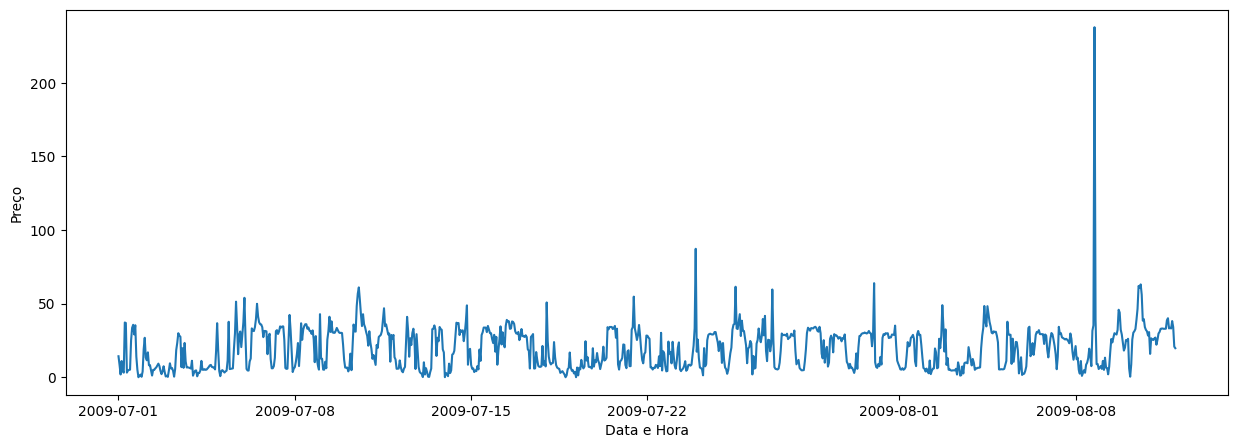

In [24]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.ylabel('Preço')
plt.xlabel('Data e Hora')
plt.show()

In [25]:
#Torna a Coluna DateTime o índice do DataFrame
df = df.set_index(df['DateTime'])

#Clona o DataFrame e Normaliza as Colunas pela primeira amostra
df_clone = df[:]
df_clone['Preco'] = df['Preco'] / df['Preco'].iloc[0]

#Copia apenas as colunas de interesse do Clone para o novo DataFrame
df_norm = df_clone[['Preco']]

#Clona o DataFrame normalizado para um novo
df_lagged = df_norm[:]

#Determina os atrasos (em amostras)
lag = 1

#Gera o DataFrame com as Colunas de Atraso
df_lagged = df_norm.assign(**{f'{col}_t-{lag}': df_norm[col].shift(lag) for col in df_norm})

#Exclui valor NaN
df_proc = df_lagged.dropna()

#Mostra dados mais recentes
df_proc

,Preco,Preco_t-1
DateTime,,
2009-07-01 01:00:00,0.591579,1.000000
2009-07-01 02:00:00,0.131930,0.591579
2009-07-01 03:00:00,0.771930,0.131930
2009-07-01 04:00:00,0.295439,0.771930
2009-07-01 05:00:00,0.216140,0.295439
...,...,...
2009-08-11 19:00:00,2.324211,2.353684
2009-08-11 20:00:00,2.676491,2.324211
2009-08-11 21:00:00,2.388772,2.676491


In [26]:
#Define as colunas que serão variáveis de entrada - explicativas
features = df_proc.columns[[1]]
features

Index(['Preco_t-1'], dtype='object')

In [27]:
#Define as coluna que será variável de saída - interesse
target = df_proc.columns[[0]]
target

Index(['Preco'], dtype='object')

In [28]:
#Separação de Dados para Ajuste e Validação dos Modelos
df_t_ajuste = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao = df_proc['2009-08-01 00:00:00':].index.values
df_dados_ajuste = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao = df_proc['2009-08-01 00:00:00':]

X_ajuste = df_dados_ajuste[features].values
Y_ajuste = df_dados_ajuste[target].values
X_validacao = df_dados_validacao[features].values
Y_validacao = df_dados_validacao[target].values

In [32]:
# Parametrização de Modelo SARIMA
from scipy import stats
from statsmodels.tsa.statespace.sarimax import SARIMAX
SARIMA_model = SARIMAX(endog=X_ajuste, order=(2, 2, 1), seasonal_order=(2,2,1,7)) #order = (p,d,q) seasonal_order=(P,D,Q,m) --> m é a quantidade de amostras necessárias para que um período sazonal se repita
SARIMA_param = SARIMA_model.fit()

# Obtém os resíduos do modelo e remove valores inválidos
residuos = np.asarray(SARIMA_param.resid)
residuos = residuos[np.isfinite(residuos)]

# Calcula Jarque-Bera
jb_stat, jb_pvalor = stats.jarque_bera(residuos)

# Calcula Shapiro-Wilk
sw_stat, sw_pvalor = stats.shapiro(residuos)

# Calcula assimetria e curtose excedente
skewness = stats.skew(residuos, bias=False)
kurtosis = stats.kurtosis(residuos, fisher=True, bias=False)

# Exibe indicadores
print(f"AIC:          {SARIMA_param.aic:.4f}")
print(f"BIC:          {SARIMA_param.bic:.4f}")
print(f"Jarque-Bera:  {jb_stat:.4f} (p-valor: {jb_pvalor:.4g})")
print(f"Shapiro-Wilk: {sw_stat:.4f} (p-valor: {sw_pvalor:.4g})")
print(f"Skewness:     {skewness:.4f}")
print(f"Kurtosis:     {kurtosis:.4f}")

AIC:          1745.1398
BIC:          1777.2623
Jarque-Bera:  456.5366 (p-valor: 7.317e-100)
Shapiro-Wilk: 0.9511 (p-valor: 5.545e-15)
Skewness:     -0.0762
Kurtosis:     3.8712


**IMPORTANTE OBSERVAR VALORES DOS TESTES DE JARQUE-BERA E SHAPIRO-WILK**

VALORES < 0,05 --> REJEITA-SE A HIPÓTESE DE NORMALIDADE

VALORES >= 0,05 --> NÃO SE REJEITA A HIPÓTESE DE NORMALIDADE

SE HIPÓTESE FOR REJEITADA, PROVAVELMENTE HAVERÁ ASSIMETRIA E/OU KURTOSIS (ACIMA DE ZERO)

In [30]:
df_previsto_SARIMA = SARIMA_param.predict(start=len(X_validacao), end=len(X_validacao)+len(X_validacao)-1)
df_previsto_SARIMA_denorm = df_previsto_SARIMA * df['Preco'].iloc[0]

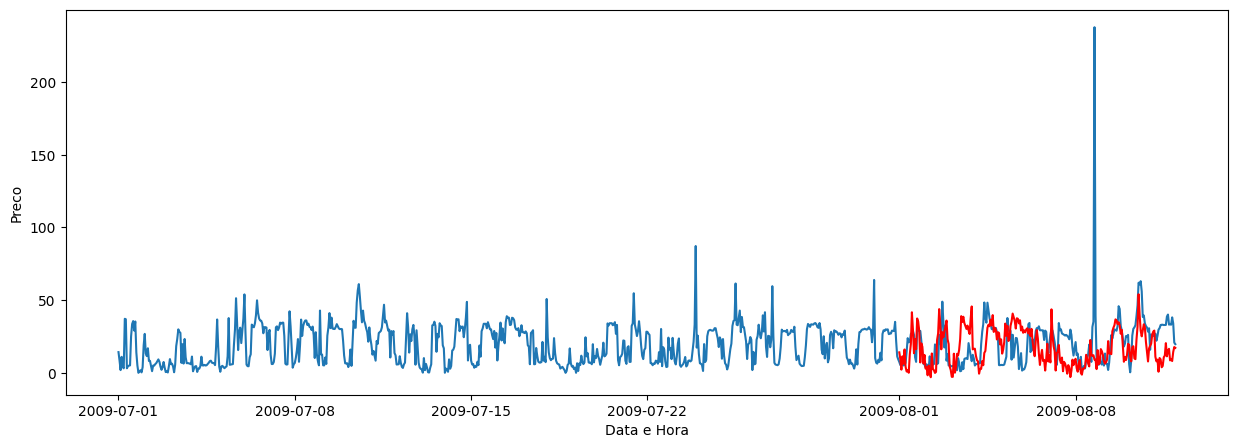

In [31]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.plot(df_t_validacao, df_previsto_SARIMA_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.show()